# Password OCR: synthetic pretraining + real fine-tuning

Pipeline: **real crops** (`data/crops.jsonl`, made by `build_crops.py`) are split *by string*. A CRNN+CTC recognizer is
(1) pretrained on on-the-fly **synthetic** panels that imitate the display + phone photo, then
(2) fine-tuned on real train crops mixed with synthetic. Everything is scored on the held-out real **test** split
and compared with the RapidOCR baseline (47.8% exact on all crops).

Set `QUICK=1` in the environment for a tiny smoke-test run. Kernel: **Python (venv)** (CUDA torch).

In [1]:
import os, json, math, random, time, string, subprocess, collections
from pathlib import Path
from functools import lru_cache
import numpy as np, cv2, torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image, ImageDraw, ImageFont
from fontTools.ttLib import TTFont
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import threading, contextlib, __main__

# ================= status reporting: every cell prints what it is doing, how long it took, and WHY if it fails =================
T0 = time.time()
def say(msg=""): print(f"[{time.strftime('%H:%M:%S')} +{time.time()-T0:5.0f}s] {msg}", flush=True)
HB = {"t": time.time(), "what": "", "active": False, "alive": None}      # heartbeat shared with the watchdog thread
def beat(what=None):
    HB["t"] = time.time()
    if what: HB["what"] = what
def _watchdog():                                                          # prints a message when a running cell makes no progress for 20 s
    while True:
        time.sleep(10); idle = time.time() - HB["t"]
        if HB["active"] and idle > 20:
            say(f"   ... still busy: '{HB['what']}' (no progress for {idle:.0f}s) | load avg {os.getloadavg()[0]:.1f} on {os.cpu_count()} CPUs"
                + (f" | data workers alive: {HB['alive']}" if HB["alive"] else "")
                + (" | normal while workers start and generate the first batches" if "first batch" in HB["what"] else ""))
if not globals().get("_WATCHDOG_ON"):
    threading.Thread(target=_watchdog, daemon=True).start(); _WATCHDOG_ON = True
def hint_for(e):
    m = f"{type(e).__name__}: {e}"
    if isinstance(e, NameError): return "a variable from an earlier cell is missing - run the cells above first (a kernel restart clears everything)."
    if isinstance(e, FileNotFoundError): return f"file not found. Working dir is {os.getcwd()}; start the notebook in the project folder, and run build_crops.py so data/crops.jsonl exists."
    if "out of memory" in m.lower(): return "GPU out of memory: lower the batch size (bs=...) or free GPU memory held by other processes (see nvidia-smi)."
    if "worker" in m.lower() and ("exited" in m.lower() or "killed" in m.lower() or "died" in m.lower()): return "a DataLoader worker process died (often RAM pressure). Lower NW in the first cell (e.g. NW = 4) and re-run the cell."
    if "CUDA" in m or "cuda" in m: return "CUDA problem: check nvidia-smi, restart the kernel, or force the CPU with DEV = 'cpu' to test."
    if isinstance(e, KeyError): return "a key/column is missing - the data files may be from an older run (re-run build_crops.py)."
    return None
@contextlib.contextmanager
def stage(name, needs=()):
    missing = [n for n in needs if n not in vars(__main__)]
    if missing:
        say(f"X {name}: CANNOT RUN - not defined yet: {missing}. A cell above has not been run in this kernel (kernel restarted?). Run the cells above this one first, in order.")
        raise RuntimeError(f"{name}: missing {missing}; run the earlier cells first")
    t0 = time.time(); HB.update(active=True, t=time.time(), what=name, alive=None)
    say(f">> {name}: started")
    try: yield
    except KeyboardInterrupt:
        say(f"## {name}: INTERRUPTED by you after {time.time()-t0:.0f}s"); raise
    except BaseException as e:
        say(f"X {name}: FAILED after {time.time()-t0:.0f}s -> {type(e).__name__}: {e}")
        w = hint_for(e)
        if w: say(f"   why / what to do: {w}")
        raise
    else: say(f"OK {name}: done in {time.time()-t0:.1f}s")
    finally: HB["active"] = False
PRINT_EVERY = 3 if os.environ.get("QUICK") == "1" else 10               # seconds between progress lines while training

SEED = 0
QUICK = os.environ.get("QUICK") == "1"                      # tiny smoke-test run

# ---------------- switches (edit these) ----------------
USE_SYNTHETIC  = os.environ.get("SYNTHETIC", "1") == "1"    # False -> camera photos only: no generator, no stage 1, no synthetic mixing
RETRAIN_STAGE1 = QUICK or os.environ.get("RETRAIN1") == "1" # False -> reuse data/stage1.pt if nothing relevant changed
RETRAIN_STAGE2 = QUICK or os.environ.get("RETRAIN2") == "1" # False -> reuse data/stage2.pt if nothing relevant changed
RUN_ABLATION   = os.environ.get("ABLATION") == "1"          # real-only vs synthetic-pretrained learning curve (slow, optional)
USE_PHONE      = os.environ.get("PHONE", "1") == "1"        # also use the labelled phone photos in data/reader_log (made with the 8444 app) as real data
PHONE_REPEAT   = 0                                          # extra copies of phone-photo training items (they are few but closest to real use)
HOLDOUT_SETUPS = [x for x in os.environ.get("HOLDOUT", "").split(",") if x]   # capture setups kept OUT of training entirely and scored separately, e.g. ["desk-holder2"]
ROOT = Path(".").resolve(); DATA = ROOT / "data"
CKP = "quick_" if QUICK else ""                               # checkpoint prefix (smoke runs never touch real checkpoints)
import hashlib
def cfg_hash(*parts): return hashlib.md5(json.dumps(parts, sort_keys=True, default=str).encode()).hexdigest()[:10]
def try_load(path, h):
    """Return cached weights if the checkpoint exists AND was trained with the same config/data, else None."""
    if not path.exists(): say(f"   no checkpoint {path.name} yet -> will train"); return None
    d = torch.load(path, map_location="cpu")
    if d.get("hash") == h: say(f"   found {path.name} (config hash {h} matches) -> loading it instead of training"); return d["state"]
    say(f"   found {path.name} but it was trained with a different config/data (stored {d.get('hash')} vs now {h}) -> will retrain"); return None
AUG_VERSION = "v6-glow"        # bump if you edit the synthetic generator / augmentation so stale checkpoints are not reused
IMG_H, IMG_W = 80, 384                      # network input (grayscale)
PW, PH = 640, 206                           # synthetic panel size (same ~3.1:1 aspect as real crops)
CHARS = string.ascii_letters + string.digits + "!@#$%^&*()-_=+[]{};:'\",.<>/?\\|`~"
C2I = {c: i + 1 for i, c in enumerate(CHARS)}     # 0 = CTC blank
NCLS = len(CHARS) + 1
DEV = "cuda" if torch.cuda.is_available() else "cpu"
NW = 4 if QUICK else 16                      # dataloader workers
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
say(f"setup ok | {len(CHARS)} chars | device {DEV} {torch.cuda.get_device_name(0) if DEV == 'cuda' else ''} | {NW} data workers | cwd {os.getcwd()}")
say(f"switches: USE_PHONE={USE_PHONE}  USE_SYNTHETIC={USE_SYNTHETIC}  RETRAIN_STAGE1={RETRAIN_STAGE1}  RETRAIN_STAGE2={RETRAIN_STAGE2}  RUN_ABLATION={RUN_ABLATION}  QUICK={QUICK}")

[13:22:34 +    0s] setup ok | 94 chars | device cuda NVIDIA GB10 | 16 data workers | cwd /data/jupyter-workspace/model-training/ocr-camera
[13:22:34 +    0s] switches: USE_PHONE=True  USE_SYNTHETIC=True  RETRAIN_STAGE1=False  RETRAIN_STAGE2=False  RUN_ABLATION=False  QUICK=False


## 1. Real data and split by string

In [2]:
with stage('1. Load real data', needs=()):
    real = [json.loads(l) for l in open(DATA / "crops.jsonl")]
    for r in real: r.setdefault("setup", "initial")                           # photos taken before setup labels existed
    if USE_PHONE:
        from phone_data import load_phone_records
        ph, skipped = load_phone_records(DATA, CHARS); real += ph
        say(f"phone photos: {len(ph)} labelled reads of {len({r['item_id'] for r in ph})} strings from data/reader_log" + (f" ({skipped} skipped: unusual characters or missing file)" if skipped else ""))
    split_of = {}                                                            # split BY STRING, separately for phone photos and display crops so both are in every split
    for grp in (lambda r: r["setup"] == "phone-field", lambda r: r["setup"] != "phone-field"):
        ids = sorted({r["item_id"] for r in real if grp(r) and r["setup"] not in HOLDOUT_SETUPS})
        random.Random(SEED).shuffle(ids); m = len(ids); c1, c2 = int(.8 * m), int(.9 * m)
        split_of |= {i: "train" for i in ids[:c1]} | {i: "val" for i in ids[c1:c2]} | {i: "test" for i in ids[c2:]}
    n = len(split_of)
    for k, r in enumerate(real): r["split"] = "ood" if r["setup"] in HOLDOUT_SETUPS else split_of[r["item_id"]]; r["idx"] = k
    json.dump({r["item_id"]: r["split"] for r in real}, open(DATA / (CKP + "split.json"), "w"))     # eval_reader_log.py uses this to score held-out strings only
    say(f"read {len(real)} crops from crops.jsonl -> {dict(collections.Counter(r['split'] for r in real))} (split by string, {n} unique strings in train/val/test)")
    say(f"photos per setup: {dict(collections.Counter(r['setup'] for r in real))} | held-out setups: {HOLDOUT_SETUPS or 'none'}")

    def load_gray(r, w=IMG_W * 2, h=int(IMG_W * 2 / 3.1)):
        im = cv2.imread(str(DATA / r["crop"]), cv2.IMREAD_GRAYSCALE)
        return cv2.resize(im, (w, h), interpolation=cv2.INTER_AREA)
    say("loading and resizing crop images ...")
    for r in tqdm(real, desc="loading crops", leave=False): r["img"] = load_gray(r)            # kept at 2x network width for augmentation headroom
    say(f"loaded {len(real)} images into memory ({sum(r['img'].nbytes for r in real)/1e6:.0f} MB)")

[13:22:34 +    0s] >> 1. Load real data: started
[13:22:34 +    0s] phone photos: 1433 labelled reads of 1386 strings from data/reader_log
[13:22:34 +    0s] read 2389 crops from crops.jsonl -> {'train': 1895, 'val': 245, 'test': 249} (split by string, 2342 unique strings in train/val/test)
[13:22:34 +    0s] photos per setup: {'desk-holder2a': 956, 'phone-field': 1433} | held-out setups: none
[13:22:34 +    0s] loading and resizing crop images ...


loading crops:   0%|          | 0/2389 [00:00<?, ?it/s]

[13:23:04 +   30s]    ... still busy: '1. Load real data' (no progress for 30s) | load avg 16.4 on 20 CPUs
[13:23:14 +   40s]    ... still busy: '1. Load real data' (no progress for 40s) | load avg 20.4 on 20 CPUs
[13:23:16 +   42s] loaded 2389 images into memory (453 MB)
[13:23:16 +   42s] OK 1. Load real data: done in 42.1s


## 2. Fonts (a slice is held out of synthetic training to test font generalisation)

In [3]:
with stage('2. Scan fonts', needs=('real',)):
    def discover_fonts():
        out = subprocess.run(["fc-list", "--format", "%{file}|%{family[0]}|%{style[0]}\n"], capture_output=True, text=True).stdout.splitlines()
        need = set(ord(c) for c in CHARS); fonts, seen = [], set()
        for line in tqdm(out, desc="scanning fonts", leave=False):
            try: path, fam, style = line.split("|")
            except ValueError: continue
            if not path.lower().endswith((".ttf", ".otf")) or path in seen: continue
            seen.add(path)
            if any(k in fam.lower() for k in ("dingbat", "symbol", "emoji", "wingding", "icon")): continue
            try:
                if not need.issubset((TTFont(path, lazy=True, fontNumber=0).getBestCmap() or {}).keys()): continue
                f = ImageFont.truetype(path, 40); l = Image.new("L", (80, 60)); ImageDraw.Draw(l).text((5, 5), "Ag0O", font=f, fill=255)
                if l.getbbox() is None: continue
            except Exception: continue
            fonts.append({"path": path, "family": fam, "style": style})
        return fonts
    if USE_SYNTHETIC:
        FONTS = discover_fonts()
        fams = sorted({f["family"] for f in FONTS}); HELD_FAMS = set(fams[::7])          # ~14% of families
        SYN_FONTS = [f for f in FONTS if f["family"] not in HELD_FAMS]
        say(f"{len(FONTS)} usable fonts, {len(fams)} families; {len(HELD_FAMS)} families held out of synthetic training -> synthetic uses {len(SYN_FONTS)} fonts")
    else:
        FONTS, SYN_FONTS, HELD_FAMS = [], [], set(); say("SKIPPED font scan: USE_SYNTHETIC is False")

[13:23:16 +   42s] >> 2. Scan fonts: started


scanning fonts:   0%|          | 0/436 [00:00<?, ?it/s]

[13:23:17 +   43s] 203 usable fonts, 90 families; 13 families held out of synthetic training -> synthetic uses 168 fonts
[13:23:17 +   43s] OK 2. Scan fonts: done in 0.5s


## 3. Synthetic generator
`render_panel` mimics the display page (same text distribution, light/dark mode only, glyph size capped so it does not depend on string length). `photo_aug` then mimics the capture:
the panel is shrunk (small panel or far phone = few pixels per letter), degraded **in photo space** (blur, noise, moiré, lighting, JPEG) with at most a ~1.5° tilt and no perspective, and rectified again with slightly wrong
corners, exactly like the real marker-based crop. That reproduces the real anisotropic blur on the far side of the panel.

In [4]:
with stage('3. Define synthetic generator', needs=()):
    CONFUSABLE = list("O0oIl1|S5sB8Z2zrnmvwVW`'.,:;gq9CcUuKkXxPp")
    def rand_text(rng):
        n = int(rng.choice([6, 8, 8, 10, 12, 12, 14, 16, 16, 20, 24])); m = rng.random()
        pool = (string.ascii_letters + string.digits if m < .2 else string.ascii_lowercase + string.digits if m < .35 else
                string.ascii_uppercase + string.digits if m < .45 else "0123456789abcdef" if m < .55 else CHARS)
        out = []
        for _ in range(n):
            if rng.random() < .3:
                c = CONFUSABLE[rng.integers(len(CONFUSABLE))]
                if c not in pool: c = pool[rng.integers(len(pool))]
            else: c = pool[rng.integers(len(pool))]
            out.append(c)
        return "".join(out)

    def _lum(c):
        c = np.array(c) / 255; c = np.where(c <= .03928, c / 12.92, ((c + .055) / 1.055) ** 2.4)
        return .2126 * c[0] + .7152 * c[1] + .0722 * c[2]
    def _contrast(a, b):
        la, lb = sorted((_lum(a), _lum(b)), reverse=True); return (la + .05) / (lb + .05)
    def rand_colors(rng):                                  # people use light mode or dark mode; no coloured backgrounds
        if rng.random() < .5:  v = int(rng.integers(235, 256)); f = int(rng.integers(0, 60));  return (v, v, v), (f, f, f)       # light mode
        v = int(rng.integers(0, 40)); f = int(rng.integers(205, 256)); return (v, v, v), (f, f, f)                          # dark mode

    @lru_cache(maxsize=4096)
    def load_font(path, size): return ImageFont.truetype(path, size)

    CAP_FRAC = .13        # glyph size never exceeds 13% of panel width, so short strings are NOT blown up to fill the panel (same rule as /display)
    def render_panel(text, font_path, bg, fg, size_frac, spacing, rot):
        f100 = load_font(font_path, 100); w100 = sum(f100.getlength(c) for c in text) + spacing * 100 * len(text)
        px = max(8, int(round(min(100 * .9 * PW / max(w100, 1), CAP_FRAC * PW, .8 * PH / 1.2) * size_frac)))
        f = load_font(font_path, px); adv = [f.getlength(c) for c in text]; tw = sum(adv) + spacing * px * len(text)
        layer = Image.new("L", (PW, PH), 0); d = ImageDraw.Draw(layer); x = (PW - tw) / 2
        asc, desc = f.getmetrics(); y = (PH - (asc + desc)) / 2
        for c, a in zip(text, adv): d.text((x, y), c, font=f, fill=255); x += a + spacing * px
        if abs(rot) > .05: layer = layer.rotate(rot, resample=Image.BICUBIC, center=(PW / 2, PH / 2))
        m = np.asarray(layer, np.float32)[..., None] / 255
        return (np.array(bg, np.float32) * (1 - m) + np.array(fg, np.float32) * m).astype(np.uint8)

    def _ss_mask(draw_fn, scale=3):                      # anti-aliased shape mask: draw at 3x, shrink
        big = Image.new("L", (PW * scale, PH * scale), 0); draw_fn(ImageDraw.Draw(big), scale)
        return np.asarray(big.resize((PW, PH), Image.LANCZOS), np.float32) / 255

    def render_field_panel(text, font_path, bg, fg, size_frac, spacing, rng):
        """What a phone sees when it frames a real password field: rounded outline, small LEFT-aligned text, sometimes a badge/icon."""
        dark = bg[0] < 128; page = np.array(bg, np.float32)
        fill = np.clip(page + rng.uniform(-6, 10) * (-1 if dark else 1), 0, 255)                 # field interior slightly different from the page
        h = PH * rng.uniform(.42, .72); top = PH / 2 - h / 2 + PH * rng.uniform(-.2, .2)
        xl = PW * rng.uniform(.02, .3); xr = PW * rng.uniform(.82, 1.15); rad = h / 2 * rng.uniform(.3, 1.)
        bw = rng.uniform(1.0, 3.0); tint = rng.uniform(-25, 25)
        line = np.clip(page + (70 if dark else -70) * rng.uniform(.5, 1.2) + np.array([-tint, 0, tint]), 0, 255)
        inner = _ss_mask(lambda d, k: d.rounded_rectangle([xl * k, top * k, xr * k, (top + h) * k], rad * k, fill=255))
        outer = _ss_mask(lambda d, k: (d.rounded_rectangle([xl * k, top * k, xr * k, (top + h) * k], rad * k, fill=255),
                                       d.rounded_rectangle([(xl + bw) * k, (top + bw) * k, (xr - bw) * k, (top + h - bw) * k], max(1, rad - bw) * k, fill=0)))
        img = page[None, None] * (1 - inner[..., None]) + fill[None, None] * inner[..., None]
        img = img * (1 - outer[..., None]) + line[None, None] * outer[..., None]
        pad = h * rng.uniform(.3, .6); x0 = xl + pad; avail = min(xr, PW) - x0 - PW * .04
        badge = rng.random() < .3 and avail > PW * .45
        if badge: avail -= PW * rng.uniform(.14, .22)
        f100 = load_font(font_path, 100); w100 = sum(f100.getlength(c) for c in text) + spacing * 100 * len(text)
        fit = min(100 * avail / max(w100, 1), CAP_FRAC * PW, .8 * h / 1.2); px = max(8, int(round(max(fit * size_frac, min(fit, 24)))))     # never shrink below ~24px unless the string itself needs it
        f = load_font(font_path, px); adv = [f.getlength(c) for c in text]; asc, desc = f.getmetrics()
        layer = Image.new("L", (PW, PH), 0); d = ImageDraw.Draw(layer); x = x0; y = top + h / 2 - (asc + desc) / 2
        for c, a in zip(text, adv): d.text((x, y), c, font=f, fill=255); x += a + spacing * px
        m = np.asarray(layer, np.float32)[..., None] / 255
        img = img * (1 - m) + np.array(fg, np.float32)[None, None] * m
        if badge or rng.random() < .2:                                                           # strength badge / eye / star icon
            cx = min(xr, PW) - PW * .05 - (PW * .1 if badge else 0); cy = top + h / 2; r = h * rng.uniform(.18, .3)
            col = np.array([int(rng.integers(40, 200))] * 3, np.float32)
            if badge:
                bm = _ss_mask(lambda d, k: d.rounded_rectangle([(cx - PW * .09) * k, (cy - r) * k, (cx + PW * .09) * k, (cy + r) * k], r * k, fill=255))
            else:
                bm = _ss_mask(lambda d, k: d.regular_polygon((cx * k, cy * k, r * k), int(rng.choice([4, 8, 30])), fill=255))
            img = img * (1 - bm[..., None]) + col[None, None] * bm[..., None]
        return np.clip(img, 0, 255).astype(np.uint8)

    ROT_MAX = 10.   # degrees. The web app's guide-box crop is NOT straightened by markers, so a tilted phone gives a tilted crop.
    def tilt(img, rng, p=.85):
        if rng.random() > p: return img
        h, w = img.shape[:2]; M = cv2.getRotationMatrix2D((w / 2, h / 2), rng.uniform(-ROT_MAX, ROT_MAX), 1.0)
        return cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)

    def photo_aug(panel, rng):
        h, w = panel.shape[:2]; CW, CH = int(w * 1.3), int(h * 1.7)
        page = int(rng.integers(100, 210)); cx, cy = CW / 2, CH / 2
        s = rng.uniform(.6, .85); qw, qh = w * s, h * s
        q = np.float32([[-qw/2, -qh/2], [qw/2, -qh/2], [qw/2, qh/2], [-qw/2, qh/2]])
        t = 0.; side = rng.integers(4)                                                    # no perspective: the marker rectification removes it
        if side == 0:   q[0, 1] *= 1 - t; q[1, 1] *= 1 - t
        elif side == 1: q[2, 1] *= 1 - t; q[3, 1] *= 1 - t
        elif side == 2: q[0, 0] *= 1 - t; q[3, 0] *= 1 - t
        else:           q[1, 0] *= 1 - t; q[2, 0] *= 1 - t
        a = np.deg2rad(rng.uniform(-1.5, 1.5)); R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]], np.float32)
        quad = (q @ R.T + [cx + rng.uniform(-.05, .05) * CW, cy + rng.uniform(-.05, .05) * CH]).astype(np.float32)
        rect = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
        photo = cv2.warpPerspective(panel, cv2.getPerspectiveTransform(rect, quad), (CW, CH), flags=cv2.INTER_LINEAR,
                                    borderMode=cv2.BORDER_CONSTANT, borderValue=(page,) * 3).astype(np.float32)
        yy, xx = np.mgrid[0:CH, 0:CW].astype(np.float32)
        th = rng.uniform(0, 2 * np.pi); photo *= (1 + rng.uniform(0, .2) * ((xx / CW - .5) * np.cos(th) + (yy / CH - .5) * np.sin(th)))[..., None]   # lighting
        r = rng.random()                                                                  # moire: screen pixel grid x camera sensor
        if r < .75:
            kind = rng.integers(3); amp = rng.uniform(.04, .15) if r < .45 else rng.uniform(.15, .45)    # a quarter of samples get strong fringes
            if kind == 0:   ph = 2 * np.pi * rng.uniform(.12, .5) * (xx * np.cos(th0 := rng.uniform(-.25, .25)) + yy * np.sin(th0)); wave = np.sin(ph)                   # fine near-vertical stripes
            elif kind == 1: wave = np.sin(2 * np.pi * rng.uniform(.01, .06) * np.hypot(xx - rng.uniform(0, CW), yy - rng.uniform(0, CH)))                               # curved interference rings
            else:           wave = np.sin(2 * np.pi * rng.uniform(.15, .45) * xx + 2.5 * np.sin(2 * np.pi * rng.uniform(.004, .02) * yy + rng.uniform(0, 6)))                  # wavy stripes
            photo *= (1 + amp * wave)[..., None]; photo += rng.uniform(0, 14) * np.sin(2 * np.pi * rng.uniform(.05, .3) * (xx * np.cos(th) + yy * np.sin(th)))[..., None]
        photo *= rng.uniform(.9, 1.1, 3)[None, None]                                      # colour cast
        k = rng.random()
        if k < .3: photo = cv2.GaussianBlur(photo, (0, 0), rng.uniform(.3, 1.2))
        elif k < .65:                                                                     # camera out of focus: disc-shaped (defocus) blur, mild to heavy
            rr = int(rng.integers(2, 6)); D = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * rr + 1, 2 * rr + 1)).astype(np.float32); photo = cv2.filter2D(photo, -1, D / D.sum())
            if rng.random() < .4: photo = cv2.GaussianBlur(photo, (0, 0), rng.uniform(.5, 1.5))
        elif k < .75:                                                                      # motion blur
            L = int(rng.integers(3, 6)); K = np.zeros((L, L), np.float32); K[L // 2, :] = 1 / L
            M = cv2.getRotationMatrix2D((L / 2 - .5, L / 2 - .5), rng.uniform(0, 180), 1); photo = cv2.filter2D(photo, -1, cv2.warpAffine(K, M, (L, L)))
        if rng.random() < .7:                                                             # small panel / far phone: few pixels per letter, then upscaled by the crop
            f = rng.uniform(.3, 1.0); photo = cv2.resize(cv2.resize(photo, None, fx=f, fy=f, interpolation=cv2.INTER_AREA), (CW, CH), interpolation=cv2.INTER_CUBIC)
        dark_page = float(panel.mean()) < 110
        if rng.random() < (.75 if dark_page else .2):                                     # halation: bright text glows when a screen is photographed
            hi = np.clip(photo - 100, 0, None); photo += rng.uniform(.3, 1.3) * cv2.GaussianBlur(hi, (0, 0), rng.uniform(2, 9))
        if dark_page and rng.random() < .75:                                              # auto-exposure lifts the blacks to mid-grey; vignette
            vg = 1 - rng.uniform(0, .35) * (((xx / CW - .5) ** 2 + (yy / CH - .5) ** 2) * 4)
            photo = photo * vg[..., None] * rng.uniform(.85, 1.0) + rng.uniform(15, 85)
        photo = (photo - 128) * rng.uniform(.85, 1.1) + 128 + rng.uniform(-15, 15)
        photo += rng.normal(0, rng.uniform(0, 3), photo.shape)
        photo = np.clip(photo, 0, 255) ** 1 
        g = rng.uniform(.85, 1.2); photo = 255 * (photo / 255) ** g
        ok, enc = cv2.imencode(".jpg", np.clip(photo, 0, 255).astype(np.uint8), [cv2.IMWRITE_JPEG_QUALITY, int(rng.integers(70, 97))])
        photo = cv2.imdecode(enc, cv2.IMREAD_COLOR)
        det = quad + rng.normal(0, .008, quad.shape) * [w, h]                             # imperfect marker localisation
        out = cv2.warpPerspective(photo, cv2.getPerspectiveTransform(det.astype(np.float32), rect), (w, h), flags=cv2.INTER_CUBIC)
        return tilt(out, rng)

    def to_input(gray):                                  # uint8 HxW -> float tensor 1xHxW, per-image standardised
        g = cv2.resize(gray, (IMG_W, IMG_H), interpolation=cv2.INTER_AREA).astype(np.float32)
        return torch.from_numpy((g - g.mean()) / (g.std() + 1e-3))[None]

    def synth_sample(rng, fonts):
        text = rand_text(rng); f = fonts[rng.integers(len(fonts))]; bg, fg = rand_colors(rng)
        sp = float(rng.choice([0, 0, 0, .02, .05, .1]))
        if rng.random() < .65: panel = render_field_panel(text, f["path"], bg, fg, rng.uniform(.3, .8), sp, rng)              # password-field look
        else:                  panel = render_panel(text, f["path"], bg, fg, rng.uniform(.5, 1.0), sp, 0.)                    # plain panel (like /display)
        return text, cv2.cvtColor(photo_aug(panel, rng), cv2.COLOR_BGR2GRAY)

    def real_aug(gray, rng):                              # light augmentation of an already-rectified real crop
        h, w = gray.shape; g = gray.astype(np.float32)
        m = [int(rng.uniform(0, .04) * d) for d in (h, h, w, w)]; g = g[m[0]:h - m[1], m[2]:w - m[3]]
        M = cv2.getRotationMatrix2D((g.shape[1] / 2, g.shape[0] / 2), rng.uniform(-ROT_MAX, ROT_MAX) if rng.random() < .85 else 0., rng.uniform(.95, 1.05))
        g = cv2.warpAffine(g, M, (g.shape[1], g.shape[0]), borderMode=cv2.BORDER_REPLICATE)
        if rng.random() < .4: g = cv2.GaussianBlur(g, (0, 0), rng.uniform(.3, 1.5))
        g = (g - 128) * rng.uniform(.8, 1.2) + 128 + rng.uniform(-20, 20) + rng.normal(0, rng.uniform(0, 5), g.shape)
        return np.clip(g, 0, 255).astype(np.uint8)

[13:23:17 +   43s] >> 3. Define synthetic generator: started
[13:23:17 +   43s] OK 3. Define synthetic generator: done in 0.0s


### Sanity check: synthetic (top) vs real test crops (bottom)

[13:23:17 +   43s] >> 3b. Sanity-check figure: started


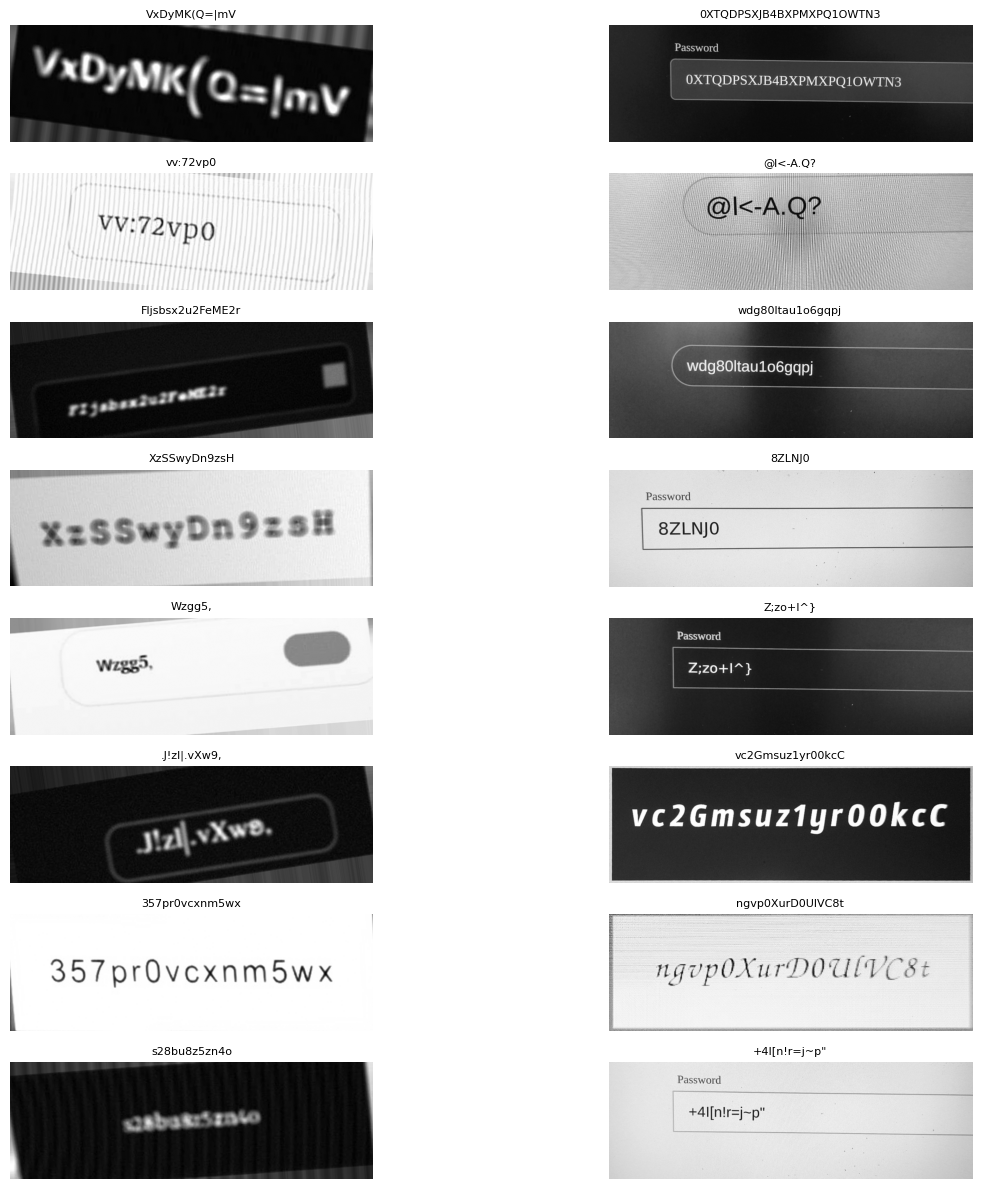

73.7 ms / synthetic sample (per core)
[13:23:26 +   52s] OK 3b. Sanity-check figure: done in 9.4s


In [5]:
with stage('3b. Sanity-check figure', needs=('real', 'SYN_FONTS', 'synth_sample')):
    if USE_SYNTHETIC:
        r_ = np.random.default_rng(1); fig, ax = plt.subplots(8, 2, figsize=(14, 12))
        for i in range(8):
            t, g = synth_sample(r_, SYN_FONTS); ax[i, 0].imshow(g, cmap="gray"); ax[i, 0].set_title(t, fontsize=8); ax[i, 0].axis("off")
            rr = random.choice([x for x in real if x["split"] == "train"]); ax[i, 1].imshow(rr["img"], cmap="gray"); ax[i, 1].set_title(rr["text"], fontsize=8); ax[i, 1].axis("off")
        plt.tight_layout(); plt.show()
        t0 = time.time(); [synth_sample(r_, SYN_FONTS) for _ in range(100)]; print(f"{(time.time()-t0)*10:.1f} ms / synthetic sample (per core)")
    else: say("SKIPPED sanity figure: USE_SYNTHETIC is False")

## 4. Datasets, model, metrics

In [6]:
with stage('4. Datasets / model / metrics', needs=('real',)):
    class SynDS(torch.utils.data.Dataset):
        def __init__(self, n, fonts): self.n, self.fonts, self.epoch = n, fonts, 0
        def __len__(self): return self.n
        def __getitem__(self, i):
            t, g = synth_sample(np.random.default_rng([SEED, self.epoch, i]), self.fonts); return to_input(g), t

    class RealDS(torch.utils.data.Dataset):
        def __init__(self, items, aug=False, repeat=1): self.items, self.aug, self.repeat, self.epoch = items, aug, repeat, 0
        def __len__(self): return len(self.items) * self.repeat
        def __getitem__(self, i):
            r = self.items[i % len(self.items)]
            g = real_aug(r["img"], np.random.default_rng([SEED, 7, self.epoch, i])) if self.aug else r["img"]
            return to_input(g), r["text"]

    def collate(b):
        x = torch.stack([a for a, _ in b]); txt = [t for _, t in b]
        tgt = torch.tensor([C2I[c] for t in txt for c in t]); ln = torch.tensor([len(t) for t in txt])
        return x, tgt, ln, txt

    def loader(ds, bs, shuffle=True, workers=NW):
        return torch.utils.data.DataLoader(ds, batch_size=bs, shuffle=shuffle, num_workers=workers, collate_fn=collate, drop_last=shuffle, pin_memory=True)

    def blk(i, o): return [nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True)]
    class CRNN(nn.Module):
        def __init__(self):
            super().__init__()
            self.cnn = nn.Sequential(*blk(1, 32), nn.MaxPool2d(2), *blk(32, 64), nn.MaxPool2d(2), *blk(64, 128), *blk(128, 128), nn.MaxPool2d((2, 1)),
                                     *blk(128, 256), *blk(256, 256), nn.MaxPool2d((2, 1)))       # -> 256 x 5 x 96
            self.proj = nn.Linear(256 * (IMG_H // 16), 256); self.rnn = nn.LSTM(256, 256, num_layers=2, bidirectional=True, batch_first=True, dropout=.2)
            self.out = nn.Linear(512, NCLS)
        def forward(self, x):
            f = self.cnn(x); b, c, h, w = f.shape
            f = self.proj(f.permute(0, 3, 1, 2).reshape(b, w, c * h)); f, _ = self.rnn(f); return self.out(f)      # B x T x NCLS

    def decode(logits):
        out = []
        for p in logits.argmax(-1).cpu().numpy():
            s, prev = [], 0
            for k in p:
                if k != prev and k != 0: s.append(CHARS[k - 1])
                prev = k
            out.append("".join(s))
        return out

    def lev(a, b):
        p = list(range(len(b) + 1))
        for i, ca in enumerate(a, 1):
            c = [i]
            for j, cb in enumerate(b, 1): c.append(min(p[j] + 1, c[j - 1] + 1, p[j - 1] + (ca != cb)))
            p = c
        return p[-1]
    def metrics(gt, pred):
        ex = np.mean([g == p for g, p in zip(gt, pred)]); ed = sum(lev(p, g) for g, p in zip(gt, pred)); return ex, 1 - ed / max(1, sum(map(len, gt)))

    @torch.no_grad()
    def predict(model, items):
        beat(f"predicting {len(items)} images"); model.eval(); preds = []
        for x, _, _, _ in loader(RealDS(items), 128, shuffle=False, workers=0): preds += decode(model(x.to(DEV)).float())
        return preds
    def evaluate(model, items):
        pred = predict(model, items); return (*metrics([r["text"] for r in items], pred), pred)

    model = CRNN().to(DEV); say(f"model built: {sum(p.numel() for p in model.parameters())/1e6:.2f}M parameters on {DEV}")
    ctc = nn.CTCLoss(blank=0, zero_infinity=True)
    tr = [r for r in real if r["split"] == "train"]; va = [r for r in real if r["split"] == "val"]; te = [r for r in real if r["split"] == "test"]; ood = [r for r in real if r["split"] == "ood"]
    say(f"splits: train {len(tr)} | val {len(va)} | test {len(te)} | held-out-setup test {len(ood)} real images")

[13:23:26 +   52s] >> 4. Datasets / model / metrics: started
[13:23:27 +   53s] model built: 4.13M parameters on cuda
[13:23:27 +   53s] splits: train 1895 | val 245 | test 249 | held-out-setup test 0 real images
[13:23:27 +   53s] OK 4. Datasets / model / metrics: done in 0.9s


## 5. Stage 1: pretrain on synthetic only
Prints the real **val** score each epoch (the real val set never enters training). Checkpoint = best real-val exact match.

In [7]:
with stage('5. Stage 1 - synthetic pretraining', needs=('model', 'tr', 'va', 'SynDS', 'RealDS', 'SYN_FONTS', 'evaluate')):
    def run_epochs(model, make_ds, epochs, lr, tag, bs=128, wd=1e-2, log=True, desc=None):
        name = desc or tag
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
        sched = None; best = (-1, None); hist = []; T_run = time.time(); ep_secs = []; warned = False
        say(f"[{name}] training for {epochs} epochs | batch {bs} | lr {lr:g} (OneCycle) | {NW} data workers | device {DEV}")
        for ep in range(epochs):
            beat(f"[{name}] epoch {ep+1}: building dataset")
            ds = make_ds(ep); dl = loader(ds, bs); nb = len(dl)
            if sched is None:
                sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epochs * nb, pct_start=.15)
                say(f"[{name}] {len(ds):,} samples per epoch -> {nb} steps per epoch, {epochs * nb:,} steps in total")
            model.train(); tot = 0.0; t_ep = time.time()
            say(f"[{name}] epoch {ep+1}/{epochs}: starting {NW} data workers ...")
            beat(f"[{name}] epoch {ep+1}: starting data workers"); it = iter(dl)
            say(f"[{name}] epoch {ep+1}/{epochs}: workers started in {time.time()-t_ep:.1f}s, waiting for the first batch ...")
            pbar = tqdm(total=nb, desc=f"[{name}] ep {ep+1}/{epochs}", leave=False, dynamic_ncols=True); last = time.time()
            for k in range(1, nb + 1):
                beat(f"[{name}] epoch {ep+1}: waiting for the first batch" if k == 1 else f"[{name}] epoch {ep+1}: waiting for batch {k}/{nb}")
                HB["alive"] = f"{sum(w.is_alive() for w in getattr(it, '_workers', []))}/{NW}"
                x, tgt, ln, _ = next(it)                      # blocks until a data worker delivers a batch
                if k == 1: say(f"[{name}] epoch {ep+1}/{epochs}: first batch arrived after {time.time()-t_ep:.1f}s (worker start-up + data generation)")
                beat(f"[{name}] epoch {ep+1}: training step {k}/{nb}")
                x = x.to(DEV, non_blocking=True)
                with torch.autocast(DEV, dtype=torch.bfloat16): lg = model(x)
                lp = lg.float().log_softmax(-1).permute(1, 0, 2)
                loss = ctc(lp, tgt.to(DEV), torch.full((x.size(0),), lp.size(0), dtype=torch.long), ln)
                opt.zero_grad(set_to_none=True); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5); opt.step(); sched.step()
                lv = loss.item(); tot += lv
                if not math.isfinite(lv) and not warned: warned = True; say(f"   WARNING: loss is {lv} at step {k} - training may be diverging (try a lower lr)")
                pbar.update(1); pbar.set_postfix(loss=f"{tot/k:.3f}"); now = time.time()
                if now - last >= PRINT_EVERY or k == nb:
                    rate = k / (now - t_ep); done = ep * nb + k
                    eta = (epochs * nb - done) / rate if not ep_secs else (epochs - ep - 1) * np.mean(ep_secs) + (nb - k) / rate
                    say(f"   [{name}] ep {ep+1}/{epochs} step {k}/{nb} ({k/nb:.0%}) | loss {tot/k:.3f} | {rate:.1f} steps/s | ETA this epoch {(nb-k)/rate:.0f}s | ETA whole run ~{eta/60:.1f} min")
                    last = now
            pbar.close(); del it
            beat(f"[{name}] epoch {ep+1}: evaluating on {len(va)} real-val images"); say(f"[{name}] epoch {ep+1}/{epochs}: training done, evaluating on {len(va)} real-val images ...")
            ex, ca, _ = evaluate(model, va); hist.append((tot / nb, ex, ca)); ep_secs.append(time.time() - t_ep)
            is_best = ex >= best[0]
            if is_best: best = (ex, {k_: v.detach().clone() for k_, v in model.state_dict().items()}); torch.save(best[1], DATA / f"{CKP}{tag}_best.pt")
            say(f"[{name}] EPOCH {ep+1}/{epochs} done | loss {tot/nb:.3f} | real-val exact {ex:.1%} char {ca:.1%}{'  (best so far, saved)' if is_best else ''} | {ep_secs[-1]:.0f}s | elapsed {(time.time()-T_run)/60:.1f} min")
            if tag == "stage1" and ep < 6 and 4.0 < tot / nb < 5.2:
                say("   note: a loss near 4.6 is the normal CTC 'predict only blanks' plateau. It usually drops sharply after ~4 epochs - keep waiting.")
        say(f"[{name}] finished {epochs} epochs in {(time.time()-T_run)/60:.1f} min | restoring best weights (real-val exact {best[0]:.1%})")
        model.load_state_dict(best[1]); return hist

    EP1, N1 = (1, 2048) if QUICK else (20, 40000)
    def mk1(ep): d = SynDS(N1, SYN_FONTS); d.epoch = ep; return d
    say(f"Stage 1 plan: {EP1} epochs x {N1:,} synthetic samples, then score on real-val each epoch. USE_SYNTHETIC={USE_SYNTHETIC}, RETRAIN_STAGE1={RETRAIN_STAGE1}")
    if USE_SYNTHETIC:
        H1 = cfg_hash("s1", IMG_H, IMG_W, EP1, N1, 1e-3, SEED, len(SYN_FONTS), sum(p.numel() for p in model.parameters()), AUG_VERSION)
        if RETRAIN_STAGE1: say("   RETRAIN_STAGE1 is True -> training (any existing checkpoint is ignored)")
        st = None if RETRAIN_STAGE1 else try_load(DATA / (CKP + "stage1.pt"), H1)
        if st is not None:
            model.load_state_dict(st); say("stage 1 SKIPPED: loaded cached checkpoint (set RETRAIN_STAGE1 = True to retrain)")
        else:
            h1 = run_epochs(model, mk1, EP1, 1e-3, "stage1")     # NB: CTC sits on a "predict only blanks" plateau (loss ~4.6) for the first ~4 epochs; normal
            torch.save({"state": model.state_dict(), "hash": H1}, DATA / (CKP + "stage1.pt"))
        S1_STATE = {k: v.detach().clone() for k, v in model.state_dict().items()}
    else:
        H1 = None; say("stage 1 SKIPPED: USE_SYNTHETIC is False (camera photos only)")

[13:23:27 +   53s] >> 5. Stage 1 - synthetic pretraining: started
[13:23:27 +   53s] Stage 1 plan: 20 epochs x 40,000 synthetic samples, then score on real-val each epoch. USE_SYNTHETIC=True, RETRAIN_STAGE1=False
[13:23:27 +   53s]    found stage1.pt but it was trained with a different config/data (stored 1070937f19 vs now 30ff6bc4c0) -> will retrain
[13:23:28 +   54s] [stage1] training for 20 epochs | batch 128 | lr 0.001 (OneCycle) | 16 data workers | device cuda
[13:23:28 +   54s] [stage1] 40,000 samples per epoch -> 312 steps per epoch, 6,240 steps in total
[13:23:28 +   54s] [stage1] epoch 1/20: starting 16 data workers ...
[13:23:30 +   56s] [stage1] epoch 1/20: workers started in 1.6s, waiting for the first batch ...


[stage1] ep 1/20:   0%|          | 0/312 [00:00<?, ?it/s]

[13:23:42 +   68s] [stage1] epoch 1/20: first batch arrived after 13.6s (worker start-up + data generation)
[13:23:45 +   71s]    [stage1] ep 1/20 step 1/312 (0%) | loss 33.840 | 0.1 steps/s | ETA this epoch 5258s | ETA whole run ~1758.2 min
[13:23:57 +   83s]    [stage1] ep 1/20 step 17/312 (5%) | loss 31.135 | 0.6 steps/s | ETA this epoch 493s | ETA whole run ~173.4 min
[13:24:09 +   95s]    [stage1] ep 1/20 step 33/312 (11%) | loss 26.605 | 0.8 steps/s | ETA this epoch 343s | ETA whole run ~127.3 min
[13:24:26 +  112s]    [stage1] ep 1/20 step 49/312 (16%) | loss 20.777 | 0.8 steps/s | ETA this epoch 310s | ETA whole run ~121.7 min
[13:24:40 +  126s]    [stage1] ep 1/20 step 65/312 (21%) | loss 16.880 | 0.9 steps/s | ETA this epoch 274s | ETA whole run ~114.3 min
[13:24:53 +  139s]    [stage1] ep 1/20 step 81/312 (26%) | loss 14.506 | 1.0 steps/s | ETA this epoch 242s | ETA whole run ~107.3 min
[13:25:07 +  153s]    [stage1] ep 1/20 step 97/312 (31%) | loss 12.892 | 1.0 steps/s | ET

[stage1] ep 2/20:   0%|          | 0/312 [00:00<?, ?it/s]

[13:30:41 +  487s] [stage1] epoch 2/20: first batch arrived after 9.6s (worker start-up + data generation)
[13:30:45 +  491s]    [stage1] ep 2/20 step 2/312 (1%) | loss 4.650 | 0.1 steps/s | ETA this epoch 2093s | ETA whole run ~161.9 min
[13:30:55 +  501s]    [stage1] ep 2/20 step 19/312 (6%) | loss 4.658 | 0.8 steps/s | ETA this epoch 363s | ETA whole run ~133.1 min
[13:31:07 +  513s]    [stage1] ep 2/20 step 35/312 (11%) | loss 4.647 | 1.0 steps/s | ETA this epoch 277s | ETA whole run ~131.6 min
[13:31:19 +  525s]    [stage1] ep 2/20 step 51/312 (16%) | loss 4.639 | 1.1 steps/s | ETA this epoch 240s | ETA whole run ~131.0 min
[13:31:31 +  537s]    [stage1] ep 2/20 step 67/312 (21%) | loss 4.631 | 1.1 steps/s | ETA this epoch 215s | ETA whole run ~130.6 min
[13:31:44 +  550s]    [stage1] ep 2/20 step 83/312 (27%) | loss 4.624 | 1.2 steps/s | ETA this epoch 198s | ETA whole run ~130.3 min
[13:31:59 +  565s]    [stage1] ep 2/20 step 101/312 (32%) | loss 4.619 | 1.2 steps/s | ETA this e

[stage1] ep 3/20:   0%|          | 0/312 [00:00<?, ?it/s]

... (31 outputs left out)

[stage1] ep 19/20:   0%|          | 0/312 [00:00<?, ?it/s]

[14:29:48 + 4034s] [stage1] epoch 19/20: first batch arrived after 7.8s (worker start-up + data generation)
[14:29:51 + 4038s]    [stage1] ep 19/20 step 3/312 (1%) | loss 0.607 | 0.3 steps/s | ETA this epoch 1182s | ETA whole run ~23.4 min
[14:30:02 + 4048s]    [stage1] ep 19/20 step 21/312 (7%) | loss 0.587 | 1.0 steps/s | ETA this epoch 301s | ETA whole run ~8.7 min
[14:30:12 + 4058s]    [stage1] ep 19/20 step 36/312 (12%) | loss 0.565 | 1.1 steps/s | ETA this epoch 245s | ETA whole run ~7.8 min
[14:30:22 + 4068s]    [stage1] ep 19/20 step 57/312 (18%) | loss 0.558 | 1.4 steps/s | ETA this epoch 188s | ETA whole run ~6.8 min
[14:30:32 + 4078s]    [stage1] ep 19/20 step 75/312 (24%) | loss 0.565 | 1.4 steps/s | ETA this epoch 165s | ETA whole run ~6.4 min
[14:30:43 + 4089s]    [stage1] ep 19/20 step 97/312 (31%) | loss 0.554 | 1.6 steps/s | ETA this epoch 139s | ETA whole run ~6.0 min
[14:30:54 + 4100s]    [stage1] ep 19/20 step 114/312 (37%) | loss 0.558 | 1.5 steps/s | ETA this epoc

[stage1] ep 20/20:   0%|          | 0/312 [00:00<?, ?it/s]

[14:33:00 + 4226s] [stage1] epoch 20/20: first batch arrived after 9.7s (worker start-up + data generation)
[14:33:01 + 4227s]    [stage1] ep 20/20 step 3/312 (1%) | loss 0.553 | 0.3 steps/s | ETA this epoch 1157s | ETA whole run ~19.3 min
[14:33:14 + 4240s]    [stage1] ep 20/20 step 20/312 (6%) | loss 0.560 | 0.8 steps/s | ETA this epoch 352s | ETA whole run ~5.9 min
[14:33:24 + 4250s]    [stage1] ep 20/20 step 41/312 (13%) | loss 0.566 | 1.2 steps/s | ETA this epoch 227s | ETA whole run ~3.8 min
[14:33:34 + 4261s]    [stage1] ep 20/20 step 58/312 (19%) | loss 0.563 | 1.3 steps/s | ETA this epoch 196s | ETA whole run ~3.3 min
[14:33:45 + 4271s]    [stage1] ep 20/20 step 77/312 (25%) | loss 0.557 | 1.4 steps/s | ETA this epoch 167s | ETA whole run ~2.8 min
[14:33:55 + 4281s]    [stage1] ep 20/20 step 94/312 (30%) | loss 0.565 | 1.4 steps/s | ETA this epoch 151s | ETA whole run ~2.5 min
[14:34:05 + 4291s]    [stage1] ep 20/20 step 109/312 (35%) | loss 0.563 | 1.4 steps/s | ETA this epoc

## 6. Stage 2: fine-tune on real train + synthetic
Real train crops are repeated (with light augmentation) and mixed with fresh synthetic samples (all fonts, including the held-out ones, are
only seen *as real crops* here, never synthetically). With `USE_SYNTHETIC = False` this stage is the whole training: real crops only, from scratch.
Training cells are gated: if a checkpoint exists and its config/data hash matches, training is skipped and the weights are loaded.

In [8]:
with stage('6. Stage 2 - fine-tune on real', needs=('model', 'tr', 'va', 'run_epochs', 'H1', 'SynDS', 'RealDS')):
    EP2, N2, REP = (1, 1024, 2) if QUICK else (30, 8000, 8)
    EP2_REAL = 1 if QUICK else 60                                  # real-only training starts from scratch, so it gets more epochs
    tr_w = tr + [r for r in tr if r["setup"] == "phone-field"] * PHONE_REPEAT          # phone photos are over-sampled
    def mk2(ep):
        r = RealDS(tr_w, aug=True, repeat=REP); r.epoch = ep
        if not USE_SYNTHETIC: return r
        s = SynDS(N2, SYN_FONTS); s.epoch = 1000 + ep
        return torch.utils.data.ConcatDataset([r, s])
    H2 = cfg_hash("s2", USE_SYNTHETIC, H1, EP2, EP2_REAL, N2, REP, PHONE_REPEAT, SEED, sorted({r["item_id"] for r in tr}), AUG_VERSION)
    S2_FILE = DATA / (CKP + ("stage2.pt" if USE_SYNTHETIC else "real_only.pt"))     # separate files: switching modes never overwrites the other model
    say(f"Stage 2 plan: " + (f"{EP2} epochs, real {len(tr_w)} imgs (incl. phone photos oversampled x{1+PHONE_REPEAT}) x {REP} repeats = {len(tr_w)*REP:,} + {N2:,} synthetic per epoch" if USE_SYNTHETIC else f"REAL ONLY from scratch, {EP2_REAL} epochs x {len(tr_w)*REP:,} real samples") + f" | checkpoint file {S2_FILE.name}")
    if RETRAIN_STAGE2: say("   RETRAIN_STAGE2 is True -> training (any existing checkpoint is ignored)")
    st = None if RETRAIN_STAGE2 else try_load(S2_FILE, H2)
    if st is not None:
        model.load_state_dict(st); say("stage 2 SKIPPED: loaded cached checkpoint (set RETRAIN_STAGE2 = True to retrain)")
    else:
        if USE_SYNTHETIC: h2 = run_epochs(model, mk2, EP2, 5e-4, "stage2", bs=64)
        else:             h2 = run_epochs(model, mk2, EP2_REAL, 1e-3, "real_only", bs=64)
        torch.save({"state": model.state_dict(), "hash": H2}, S2_FILE); say(f"saved {S2_FILE.name}")

[14:36:00 + 4406s] >> 6. Stage 2 - fine-tune on real: started
[14:36:00 + 4406s] Stage 2 plan: 30 epochs, real 1895 imgs (incl. phone photos oversampled x1) x 8 repeats = 15,160 + 8,000 synthetic per epoch | checkpoint file stage2.pt
[14:36:00 + 4406s]    found stage2.pt but it was trained with a different config/data (stored 18ed44b266 vs now 40b123d9c3) -> will retrain
[14:36:00 + 4406s] [stage2] training for 30 epochs | batch 64 | lr 0.0005 (OneCycle) | 16 data workers | device cuda
[14:36:00 + 4406s] [stage2] 23,160 samples per epoch -> 361 steps per epoch, 10,830 steps in total
[14:36:00 + 4406s] [stage2] epoch 1/30: starting 16 data workers ...
[14:36:01 + 4407s] [stage2] epoch 1/30: workers started in 0.9s, waiting for the first batch ...


[stage2] ep 1/30:   0%|          | 0/361 [00:00<?, ?it/s]

[14:36:03 + 4409s] [stage2] epoch 1/30: first batch arrived after 3.6s (worker start-up + data generation)
[14:36:11 + 4417s]    [stage2] ep 1/30 step 30/361 (8%) | loss 0.315 | 2.7 steps/s | ETA this epoch 121s | ETA whole run ~65.8 min
[14:36:21 + 4427s]    [stage2] ep 1/30 step 72/361 (20%) | loss 0.314 | 3.4 steps/s | ETA this epoch 84s | ETA whole run ~52.4 min
[14:36:31 + 4437s]    [stage2] ep 1/30 step 114/361 (32%) | loss 0.325 | 3.7 steps/s | ETA this epoch 68s | ETA whole run ~48.9 min
[14:36:41 + 4447s]    [stage2] ep 1/30 step 156/361 (43%) | loss 0.324 | 3.8 steps/s | ETA this epoch 54s | ETA whole run ~47.2 min
[14:36:51 + 4457s]    [stage2] ep 1/30 step 198/361 (55%) | loss 0.323 | 3.8 steps/s | ETA this epoch 42s | ETA whole run ~46.1 min
[14:37:01 + 4467s]    [stage2] ep 1/30 step 240/361 (66%) | loss 0.321 | 3.9 steps/s | ETA this epoch 31s | ETA whole run ~45.3 min
[14:37:11 + 4478s]    [stage2] ep 1/30 step 282/361 (78%) | loss 0.317 | 3.9 steps/s | ETA this epoch 2

[stage2] ep 2/30:   0%|          | 0/361 [00:00<?, ?it/s]

[14:37:33 + 4499s] [stage2] epoch 2/30: first batch arrived after 3.5s (worker start-up + data generation)
[14:37:41 + 4507s]    [stage2] ep 2/30 step 37/361 (10%) | loss 0.316 | 3.3 steps/s | ETA this epoch 98s | ETA whole run ~43.5 min
[14:37:51 + 4517s]    [stage2] ep 2/30 step 87/361 (24%) | loss 0.314 | 4.1 steps/s | ETA this epoch 67s | ETA whole run ~43.0 min
[14:38:01 + 4527s]    [stage2] ep 2/30 step 138/361 (38%) | loss 0.312 | 4.4 steps/s | ETA this epoch 51s | ETA whole run ~42.7 min
[14:38:11 + 4537s]    [stage2] ep 2/30 step 189/361 (52%) | loss 0.307 | 4.6 steps/s | ETA this epoch 38s | ETA whole run ~42.5 min
[14:38:21 + 4547s]    [stage2] ep 2/30 step 240/361 (66%) | loss 0.302 | 4.6 steps/s | ETA this epoch 26s | ETA whole run ~42.3 min
[14:38:31 + 4558s]    [stage2] ep 2/30 step 291/361 (81%) | loss 0.298 | 4.7 steps/s | ETA this epoch 15s | ETA whole run ~42.1 min
[14:38:41 + 4568s]    [stage2] ep 2/30 step 342/361 (95%) | loss 0.297 | 4.8 steps/s | ETA this epoch 4

[stage2] ep 3/30:   0%|          | 0/361 [00:00<?, ?it/s]

... (51 outputs left out)

[stage2] ep 29/30:   0%|          | 0/361 [00:00<?, ?it/s]

[15:12:43 + 6609s] [stage2] epoch 29/30: first batch arrived after 3.0s (worker start-up + data generation)
[15:12:51 + 6617s]    [stage2] ep 29/30 step 40/361 (11%) | loss 0.160 | 3.5 steps/s | ETA this epoch 91s | ETA whole run ~2.8 min
[15:13:01 + 6628s]    [stage2] ep 29/30 step 91/361 (25%) | loss 0.174 | 4.2 steps/s | ETA this epoch 64s | ETA whole run ~2.4 min
[15:13:12 + 6638s]    [stage2] ep 29/30 step 142/361 (39%) | loss 0.175 | 4.5 steps/s | ETA this epoch 49s | ETA whole run ~2.1 min
[15:13:22 + 6648s]    [stage2] ep 29/30 step 193/361 (53%) | loss 0.177 | 4.6 steps/s | ETA this epoch 36s | ETA whole run ~1.9 min
[15:13:32 + 6658s]    [stage2] ep 29/30 step 244/361 (68%) | loss 0.179 | 4.7 steps/s | ETA this epoch 25s | ETA whole run ~1.7 min
[15:13:42 + 6668s]    [stage2] ep 29/30 step 313/361 (87%) | loss 0.179 | 5.1 steps/s | ETA this epoch 9s | ETA whole run ~1.5 min
[15:13:47 + 6674s]    [stage2] ep 29/30 step 361/361 (100%) | loss 0.180 | 5.3 steps/s | ETA this epoch

[stage2] ep 30/30:   0%|          | 0/361 [00:00<?, ?it/s]

[15:13:51 + 6677s] [stage2] epoch 30/30: first batch arrived after 3.0s (worker start-up + data generation)
[15:13:59 + 6685s]    [stage2] ep 30/30 step 39/361 (11%) | loss 0.181 | 3.5 steps/s | ETA this epoch 91s | ETA whole run ~1.5 min
[15:14:09 + 6695s]    [stage2] ep 30/30 step 88/361 (24%) | loss 0.183 | 4.2 steps/s | ETA this epoch 66s | ETA whole run ~1.1 min
[15:14:19 + 6706s]    [stage2] ep 30/30 step 138/361 (38%) | loss 0.183 | 4.4 steps/s | ETA this epoch 51s | ETA whole run ~0.8 min
[15:14:29 + 6716s]    [stage2] ep 30/30 step 186/361 (52%) | loss 0.185 | 4.5 steps/s | ETA this epoch 39s | ETA whole run ~0.6 min
[15:14:40 + 6726s]    [stage2] ep 30/30 step 235/361 (65%) | loss 0.188 | 4.6 steps/s | ETA this epoch 28s | ETA whole run ~0.5 min
[15:14:50 + 6736s]    [stage2] ep 30/30 step 284/361 (79%) | loss 0.187 | 4.6 steps/s | ETA this epoch 17s | ETA whole run ~0.3 min
[15:15:00 + 6746s]    [stage2] ep 30/30 step 332/361 (92%) | loss 0.186 | 4.6 steps/s | ETA this epoch

## 7. Final result on the held-out real test split (strings never seen in training)

In [9]:
with stage('7. Final test evaluation', needs=('model', 'te', 'ood', 'evaluate')):
    say(f"scoring the model on {len(te)} held-out real test images ...")
    ex, ca, pred = evaluate(model, te)
    rap_file = DATA / "rapidocr_by_crop.json"; rap = json.load(open(rap_file)) if rap_file.exists() else {}
    if not rap: say("no RapidOCR baseline file (run eval_rapidocr.py) -> baseline columns skipped")
    def report(name, items, pr):
        gt = [r["text"] for r in items]; e, c = metrics(gt, pr); rp = [rap.get(r["crop"]) for r in items]
        base = ""
        if rap and all(p is not None for p in rp): re_, rc = metrics(gt, rp); base = f"   | RapidOCR exact {re_:6.1%} char {rc:6.1%}"
        print(f"{name:36} n={len(items):4d}   CRNN exact {e:6.1%} char {c:6.1%}{base}")
    report("TEST (held-out strings, all setups)", te, pred)
    for k in sorted({r["setup"] for r in te}):
        ix = [i for i, r in enumerate(te) if r["setup"] == k]; report(f"   test, setup {k}", [te[i] for i in ix], [pred[i] for i in ix])
    def _tilted(g, a):
        h, w = g.shape; return cv2.warpAffine(g, cv2.getRotationMatrix2D((w / 2, h / 2), a, 1.0), (w, h), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)
    for a in (-8, -4, 4, 8):       # guide-box crops are not marker-straightened: how much does a tilted crop hurt?
        tl = [dict(r, img=_tilted(r["img"], a)) for r in te]; e_, c_, _ = evaluate(model, tl)
        print(f"{'   test, crop tilted %+d deg' % a:36} n={len(tl):4d}   CRNN exact {e_:6.1%} char {c_:6.1%}")
    if ood:
        _, _, pood = evaluate(model, ood); report("HELD-OUT SETUP(S) " + ",".join(HOLDOUT_SETUPS), ood, pood)
    if USE_SYNTHETIC:
        held = [i for i, r in enumerate(te) if r["font"] in HELD_FAMS]; seen = [i for i, r in enumerate(te) if r["font"] not in HELD_FAMS]
        report("   test, fonts seen in synthetic", [te[i] for i in seen], [pred[i] for i in seen])
        report("   test, HELD-OUT font families", [te[i] for i in held], [pred[i] for i in held])

[15:15:07 + 6753s] >> 7. Final test evaluation: started
[15:15:07 + 6753s] scoring the model on 249 held-out real test images ...
TEST (held-out strings, all setups)  n= 249   CRNN exact  79.9% char  97.4%   | RapidOCR exact  37.3% char  75.3%
   test, setup desk-holder2a         n=  96   CRNN exact  82.3% char  96.2%   | RapidOCR exact  54.2% char  91.7%
   test, setup phone-field           n= 153   CRNN exact  78.4% char  98.0%   | RapidOCR exact  26.8% char  65.8%
   test, crop tilted -8 deg          n= 249   CRNN exact  74.3% char  96.7%
   test, crop tilted -4 deg          n= 249   CRNN exact  78.7% char  97.3%
   test, crop tilted +4 deg          n= 249   CRNN exact  77.9% char  97.4%
   test, crop tilted +8 deg          n= 249   CRNN exact  75.1% char  96.9%
   test, fonts seen in synthetic     n= 233   CRNN exact  79.8% char  97.4%   | RapidOCR exact  35.2% char  74.2%
   test, HELD-OUT font families      n=  16   CRNN exact  81.2% char  97.9%   | RapidOCR exact  68.8% char  93

### Error analysis

In [10]:
with stage('7b. Error analysis', needs=('te', 'pred')):
    pairs = collections.Counter((g, p) for r, pr in zip(te, pred) if len(r["text"]) == len(pr) for g, p in zip(r["text"], pr) if g != p)
    print("most common confusions (truth -> pred):", pairs.most_common(15))
    bad = [(r["text"], p, r["font"]) for r, p in zip(te, pred) if r["text"] != p]
    for t, p, f in bad[:15]: print(f"{t!r:28} -> {p!r:28} {f}")
    L = collections.defaultdict(list)
    for r, p in zip(te, pred): L[min(len(r["text"]) // 8 * 8, 24)].append(r["text"] == p)
    print({k: f"{np.mean(v):.0%} (n={len(v)})" for k, v in sorted(L.items())})

[15:15:09 + 6755s] >> 7b. Error analysis: started
most common confusions (truth -> pred): [(('l', 'I'), 7), (('I', 'l'), 4), (('V', 'v'), 2), (('|', 'l'), 2), (('`', "'"), 2), (('}', ')'), 2), (('*', '^'), 2), (('$', 'S'), 1), (('o', '0'), 1), (('|', 'I'), 1), (('!', 'I'), 1), ((';', ','), 1), (('1', '!'), 1), (('"', "'"), 1), (('S', '5'), 1)]
'v]s~$mKLqN@zHg?V'           -> 'v]s~SmKLqN@zHg?v'           Liberation Sans
'jIkZXBeBzRMv'               -> 'jlkZXBeBzRMv'               Khmer OS
'91ioxr'                     -> '91i0xr'                     Uroob
'd:{X:El4NuuWUTf,'           -> 'd:{X:El4NuuWUTf'            Yrsa
'S<l8`H4j?|}^mVO-[o7d'       -> 'S<I8`H4j?I}^mVO-[o7d'       Kinnari
'kJXAr(u+0vIV|PKdOv2Iks.G'   -> 'kJXAr(u+0vIVlPKdOv2Iks.G'   Norasi
'CAuo|,a:jsK8DX'             -> 'CAuol,a:jsK8DX'             aakar
'`WX8sDoJXx,"'               -> '`WX8sDoJXx,"\''             Garuda
'yesx8rkiq850wjw8'           -> '7ne6go'                     Pagul
'pKcx0th9'                   -> '7r

In [11]:
with stage('Save final model', needs=('model',)):
    FINAL = DATA / (CKP + ("crnn_final_synthetic.pt" if USE_SYNTHETIC else "crnn_final_real_only.pt"))
    torch.save({"model": model.state_dict(), "chars": CHARS, "img_hw": (IMG_H, IMG_W)}, FINAL)
    say(f"saved {FINAL.name}")

[15:15:09 + 6755s] >> Save final model: started
[15:15:10 + 6756s] saved crnn_final_synthetic.pt
[15:15:10 + 6756s] OK Save final model: done in 0.2s


## 8. (Optional) Do we still need synthetic data? Learning curve on real data
Set `RUN_ABLATION = True` in the first cell (needs `USE_SYNTHETIC = True`) to run. Compares **real-only from scratch** with **synthetic-pretrained + fine-tune**
at 25 / 50 / 100% of the real train strings. Scored on real **val** (the test split stays untouched). If the two curves meet as you add real data,
synthetic data is no longer needed.

In [12]:
with stage('8. Ablation (optional)', needs=('run_epochs', 'tr', 'te')):
    if RUN_ABLATION and USE_SYNTHETIC:
        tr_ids = sorted({r["item_id"] for r in tr}); rows = []
        for frac in (0.25, 0.5, 1.0):
            keep = set(tr_ids[:int(len(tr_ids) * frac)]); sub_tr = [r for r in tr if r["item_id"] in keep]
            rep = max(1, round(REP * len(tr) / len(sub_tr)))
            say(f"ablation: {frac:.0%} of real train strings = {len(sub_tr)} images")
            for name, init in (("real-only (scratch)", None), ("synthetic-pretrained + fine-tune", S1_STATE)):
                m = CRNN().to(DEV)
                if init is not None: m.load_state_dict(init)
                def mk(ep, sub_tr=sub_tr, rep=rep, init=init):
                    r = RealDS(sub_tr, aug=True, repeat=rep); r.epoch = ep
                    if init is None: return r
                    s = SynDS(N2, SYN_FONTS); s.epoch = 1000 + ep; return torch.utils.data.ConcatDataset([r, s])
                h = run_epochs(m, mk, EP2 if init is not None else 2 * EP2, 5e-4 if init is not None else 1e-3, "abl", bs=64, log=False, desc=f"abl {frac:.0%} {'syn+real' if init is not None else 'real-only'}")
                rows.append((frac, len(sub_tr), name, max(x[1] for x in h), max(x[2] for x in h)))
                print(f"{frac:4.0%} real ({len(sub_tr):4d} imgs)  {name:34} val exact {rows[-1][3]:.1%}  char {rows[-1][4]:.1%}")
        plt.figure(figsize=(5, 3.5))
        for name in {r[2] for r in rows}:
            pts = [(r[1], r[3]) for r in rows if r[2] == name]; plt.plot(*zip(*pts), "o-", label=name)
        plt.xlabel("# real train images"); plt.ylabel("real-val exact match"); plt.legend(); plt.grid(alpha=.3); plt.show()
    else:
        print("skipped (set RUN_ABLATION = True with USE_SYNTHETIC = True to run)")

[15:15:10 + 6756s] >> 8. Ablation (optional): started
skipped (set RUN_ABLATION = True with USE_SYNTHETIC = True to run)
[15:15:10 + 6756s] OK 8. Ablation (optional): done in 0.0s
